# hBN bilayer: the bottom layer as an effective substrate

**Goal.** GW of the top layer with the bottom layer included only through its screening (Notes, Sec. 2.1). The
screened interaction in the layer obeys Eq. (19) of the notes,
$$
W = \tilde v + \tilde v\,\chi_0^{\mathrm{L}}\,W , \qquad \tilde v = v + v\,\chi^{\mathrm{S}}\,v ,
$$
with $\chi_0^{\mathrm{L}}$ the independent-particle response of the layer and $\chi^{\mathrm{S}}$ the (interacting)
response of the substrate. Both come from GW runs already done: the top layer alone (`ML_top_AA1`, `ML_top_AB`) and
the bottom layer alone (`ML_bot`), each computed in its exact position in the same cell.

Steps:
1. the Yambo screening databases: what they contain and how to read them;
2. moving a layer: the screening of the top layer from that of the bottom layer by translation and rotation;
3. $\tilde v$, the interaction dressed by the substrate, seen on the plane of the top layer;
4. $W$ of the top layer from Eq. (19), checked against the bilayer and written as a new screening database;
5. (next) GW of the top layer with this database, and comparison with the top-layer bands extracted from the explicit
   bilayer (`Projection_Analysis.ipynb`, `results/layer_projection.json`).

Data: the PPA screening databases of the GW runs at the converged parameters (`GW_Analysis.ipynb`: k = 18x18x1,
NGsBlkXp = 6 Ha, BndsRnXp = 200 for the layers, 212 for the bilayers, slab cutoff along z).

**Tools.** The databases are handled with MPPI: `YamboScreeningParser` (reading, $\varepsilon^{-1}$ and $\chi_0$,
symmetry transformations, writer of a new database, tools for 2D systems), built from the prototype of the first
version of this notebook, `YamboCoulombParser` (the truncated $v$ of the run, from `ndb.cutoff`, needed only for the
quantities in physical units) and `YamboDftParser` (atomic positions). This notebook
keeps what is specific to the system and to the method: the operations that move the hBN layer, Eq. (19), $g(Q)$, the
real-space picture and the comparisons with the bilayer.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from mppi.Parsers import YamboDftParser, YamboScreeningParser, YamboCoulombParser
from mppi.Utilities.Constants import HaToeV

MB = 'MB_analysis'
run = {'ML_bot': 'kpoints_18-nbnds_250-ML_bot', 'ML_top_AA1': 'kpoints_18-nbnds_250-ML_top_AA1',
       'ML_top_AB': 'kpoints_18-nbnds_250-ML_top_AB', 'AA1': 'kpoints_18-nbnds_400-AA1', 'AB': 'kpoints_18-nbnds_400-AB'}
screening = {s: os.path.join(MB, run[s], 'ndb_pp-ngsblkxp_6.0-bndsrnxp_' + ('200' if s.startswith('ML') else '212'))
             for s in run}
names = {'AA1': "AA'", 'AB': 'AB'}

## 1. The screening databases

A GW run in the plasmon-pole approximation (PPA) writes the screening in a folder (here
`ndb_pp-ngsblkxp_6.0-bndsrnxp_<n>`, shared by the runs that change only $\Sigma$): the header `ndb.pp` and one
fragment per $\mathbf q$ point, with a 591 x 591 matrix (the $\mathbf G$ vectors up to 6 Ha) at the 37 $\mathbf q$ of
the IBZ and at the two frequencies of the PPA fit, $0$ and $i\,27.2$ eV, in single precision.

What $X$ is (Lumen source, `pol_function/X_redux.F`): Yambo builds $\chi_0$, solves the Dyson equation
$\chi = (1 - \chi_0 v)^{-1}\chi_0$ on this 591 x 591 block and stores the symmetrized form
$$
X_{\mathbf G\mathbf G'}(\mathbf q,\omega) = v^{1/2}_{\mathbf G}(\mathbf q)\,\chi_{\mathbf G\mathbf G'}(\mathbf q,\omega)\,
v^{1/2}_{\mathbf G'}(\mathbf q) = \varepsilon^{-1}_{\mathbf G\mathbf G'} - \delta_{\mathbf G\mathbf G'} ,
$$
with $v$ the Coulomb interaction truncated along $z$ (slab cutoff, $|z - z'| < c/2$). $\chi_0$ itself is not stored.
$v_{\mathbf G}(\mathbf q) = 4\pi/b^2_{\mathbf G}(\mathbf q)$, where $b$ = `CUT_BARE_QPG` of `ndb_rim_cutoff/ndb.cutoff`
($|\mathbf q + \mathbf G|$ modified by the cutoff, `coulomb/cutoff_slab.F`).

**Warning, `ndb.RIM_W`.** It is in the same folder, but it is not a property of the geometry only: Yambo builds it
from the $X$ of the screening database (`qp/QP_interpolate_W.F`), and reads it back if the header matches, without
checking $X$. With a modified screening database it must be recomputed: never copy it.

One `YamboScreeningParser` per database: the global data (G vectors, q points, frequencies, the symmetries of the
`SAVE`) are read at once, the matrices $X$ (order $[\omega, \mathbf G, \mathbf G']$) one $\mathbf q$ at a time with
`get_X(iq)` ($\mathbf q$ numbered from 1, as in Yambo). The truncated $v$ is not part of the screening database: one
`YamboCoulombParser` per run reads it from `ndb_rim_cutoff/ndb.cutoff` (`coulomb(iq, ng)`, on the first `ng` G vectors
of the `SAVE`, which are those of the screening database: checked below). It is needed only for the quantities in
physical units (Sec. 3).

In [2]:
scr = {s: YamboScreeningParser(screening[s], os.path.join(MB, run[s], 'SAVE'), verbose=False) for s in run}
coul = {s: YamboCoulombParser(os.path.join(MB, run[s], 'SAVE'), cutoff=os.path.join(MB, run[s], 'ndb_rim_cutoff'),
                              verbose=False) for s in run}
bot = scr['ML_bot']                                      # the only database used to build the effective W
bot.get_info()
for s in run:                                            # v and X on the same G vectors and q points
    assert np.allclose(scr[s].G, coul[s].G[:scr[s].ng]) and np.allclose(scr[s].q, coul[s].q, atol=1e-5)

same = lambda a, b: 'same' if (np.shape(a) == np.shape(b) and np.allclose(a, b, rtol=1e-6, atol=1e-8)) else 'DIFF'
bqpg = {s: np.array([coul[s].bare_qpg(iq, scr[s].ng) for iq in range(1, scr[s].nq + 1)]) for s in run}
print('%-11s %4s %9s %8s %7s %6s %6s %6s %6s %s' % ('system', 'ng', 'bands', 'kernel', 'cutoff', 'G', 'q', 'freq',
                                                     'v_cut', 'symmetries (as ML_bot)'))
for s in run:
    S, S0 = scr[s].syms, bot.syms
    sym = '%d + TR' % len(S) if scr[s].time_reversal else '%d' % len(S)
    sym += ', same' if (len(S) == len(S0) and np.allclose(S, S0, atol=1e-5)) else ', different'
    freq = same(scr[s].frequencies, bot.frequencies) if scr[s].check_frequencies() else 'DIFF(q)'
    print('%-11s %4d %9s %8s %7s %6s %6s %6s %6s %s' % (s, scr[s].ng, '%d-%d' % scr[s].bands, scr[s].kernel,
          scr[s].cutoff_geometry, same(scr[s].G, bot.G), same(scr[s].q, bot.q), freq, same(bqpg[s], bqpg['ML_bot']), sym))

Screening database MB_analysis/kpoints_18-nbnds_250-ML_bot/ndb_pp-ngsblkxp_6.0-bndsrnxp_200/ndb.pp
number of q points 37 - number of G vectors 591 - bands 1-200 - kernel HARTREE - cutoff slab z
frequencies (eV): [0. +0.j     0.+27.2114j]
system        ng     bands   kernel  cutoff      G      q   freq  v_cut symmetries (as ML_bot)


ML_bot       591     1-200  HARTREE  slab z   same   same   same   same 12 + TR, same


ML_top_AA1   591     1-200  HARTREE  slab z   same   same   same   same 12 + TR, same


ML_top_AB    591     1-200  HARTREE  slab z   same   same   same   same 12 + TR, same


AA1          591     1-212  HARTREE  slab z   same   same   same   same 12, different


AB           591     1-212  HARTREE  slab z   same   same   same   same 12 + TR, same


All the databases are on the same $\mathbf G$ block, $\mathbf q$ points, frequencies and truncated $v$, and the
three layers have the same symmetry operations in the same order (the AA' bilayer has its own 12, D3d: it is used only
for checks at the IBZ points). So the symmetrized matrices of different runs can be combined directly, without ever
writing $v$ explicitly. In particular, $\chi_0$, which is not stored, follows exactly from $X$ by inverting the Dyson
equation on the same block ($\varepsilon = (\varepsilon^{-1})^{-1}$, $\varepsilon = 1 - v\chi_0$; method `chi0`):
$$
\tilde\chi_0 \equiv v^{1/2}\chi_0\,v^{1/2} = 1 - (1 + X)^{-1} .
$$

## 2. Moving a layer: the screening of the top layer from that of the bottom layer

The top layer is the bottom layer moved: by a translation in AB, by a rotation of 180 degrees about $z$ plus a
translation in AA' (B and N exchanged). If the screening of a moved layer can be obtained from that of the layer in one
position, a single layer calculation serves every position and orientation (in the same cell); here the computed
databases of `ML_top_AA1` and `ML_top_AB` are the test.

A layer moved by $\mathbf r \to R\mathbf r + \boldsymbol\tau$ ($R$ a rotation that maps the lattice onto itself,
$\boldsymbol\tau$ any translation, also along $z$) has $\chi'(\mathbf r, \mathbf r') = \chi(R^{-1}(\mathbf r -
\boldsymbol\tau), R^{-1}(\mathbf r' - \boldsymbol\tau))$. With the plane-wave expansion of the notes this gives
$$
\chi'_{\mathbf G\mathbf G'}(\mathbf q) = e^{-i(\mathbf G - \mathbf G')\cdot\boldsymbol\tau}\,
\chi_{R^{-1}\mathbf G,\,R^{-1}\mathbf G'}(R^{-1}\mathbf q)
$$
(the phases of $\mathbf q$ cancel). At $\mathbf q = 0$ (`iq` = 1) Yambo computes the head and the wings at a small
$\mathbf q_0$ along `LongDrXp` = [1,1,0] (`X_PARS_3`, "Field direction"), so there $\mathbf q_0$ is the vector that
$R$ acts on. The truncated $v_{\mathbf G}(\mathbf q)$ depends only on $|\mathbf q_\parallel +
\mathbf G_\parallel|$ and $G_z$, so it is unchanged by in-plane rotations and $X = v^{1/2}\chi v^{1/2}$ transforms in
the same way; the slab cutoff truncates $z - z'$, so a translation along $z$ is allowed (the whole system must stay
within $|z - z'| < c/2$).
- AB: $R = 1$, only the phase.
- AA': $R = C_{2z}$, so $R^{-1}\mathbf q = -\mathbf q$, which is not stored. Time reversal gives it (reciprocity,
  $\chi(\mathbf r, \mathbf r') = \chi(\mathbf r', \mathbf r)$): $\chi_{\mathbf G\mathbf G'}(-\mathbf q) =
  \chi_{-\mathbf G', -\mathbf G}(\mathbf q)$, hence
  $X'_{\mathbf G\mathbf G'}(\mathbf q) = e^{-i(\mathbf G - \mathbf G')\cdot\boldsymbol\tau}\,X_{\sigma\mathbf G',\,\sigma\mathbf G}(\mathbf q)$,
  with $\sigma\mathbf G = -C_{2z}^{-1}\mathbf G = (G_x, G_y, -G_z)$.
- A general $R$ with $R^{-1}\mathbf q \ne \pm\mathbf q$ needs $X$ outside the IBZ, from the symmetries of the layer
  ($X_{S\mathbf G, S\mathbf G'}(S\mathbf q) = X_{\mathbf G\mathbf G'}(\mathbf q)$ for a symmorphic $S$): not needed
  here (`transform` raises `NotImplementedError`).

These are the cases of `YamboScreeningParser.transform(X, iq, rotation, translation)`. It also checks that $R$ maps the
$\mathbf G$ set onto itself and, from the cutoff written in the database, that it leaves the truncated $v$ invariant
(slab cutoff along $z$: $R$ must map $z$ onto $\pm z$). $\boldsymbol\tau$ maps the bottom B onto the top B (AB:
$\boldsymbol\tau = \mathbf r_{\mathrm{top}} - \mathbf r_{\mathrm{bot}}$; AA': $\boldsymbol\tau = \mathbf
r_{\mathrm{top}} - C_{2z}\mathbf r_{\mathrm{bot}}$); the same operation must map N onto N up to a lattice vector,
checked below through the phases.

In [3]:
save = {s: YamboDftParser(os.path.join(MB, run[s], 'SAVE', 'ns.db1'), verbose=False) for s in run if s.startswith('ML')}
atoms = {s: {p[0]: np.array(p[1], dtype=float) for p in save[s].atomic_positions} for s in save}
C2z = np.diag([-1., -1., 1.])
operation = {'AB': np.eye(3), 'AA1': C2z}

tau = {}
for bl, R in operation.items():
    t = {a: atoms['ML_top_' + bl][a] - R @ atoms['ML_bot'][a] for a in ['B', 'N']}
    tau[bl] = t['B']
    print('%-3s tau = (%.4f, %.4f, %.4f) bohr; N mapped onto N: max |e^{iG.(tau_N - tau_B)} - 1| = %.1e' % (
          names[bl], *tau[bl], abs(np.exp(1j * bot.G @ (t['N'] - t['B'])) - 1).max()))

rel = {bl: [] for bl in names}
controls = {bl: [] for bl in names}
for iq in range(1, bot.nq + 1):
    Xb = bot.get_X(iq)
    for bl, R in operation.items():
        Xt = scr['ML_top_' + bl].get_X(iq)
        Xm = bot.transform(Xb, iq, rotation=R, translation=tau[bl])
        nrm = np.linalg.norm(Xt, axis=(1, 2))
        rel[bl].append(np.linalg.norm(Xm - Xt, axis=(1, 2)) / nrm)
        wrong = bot.transform(Xb, iq, translation=atoms['ML_top_' + bl]['B'] - atoms['ML_bot']['B'])   # translation only
        controls[bl].append((np.linalg.norm(Xb - Xt, axis=(1, 2)) / nrm, np.linalg.norm(wrong - Xt, axis=(1, 2)) / nrm))
for bl in names:
    r, ctl = np.array(rel[bl]), np.array(controls[bl])
    print('%-3s ||X_moved - X_top|| / ||X_top||: w = 0 %.1e (q -> 0) and %.1e-%.1e (other q); i 27 eV %.1e-%.1e' % (
          names[bl], r[0, 0], r[1:, 0].min(), r[1:, 0].max(), r[:, 1].min(), r[:, 1].max()))
    print('     control, layer not moved: %.2f-%.2f' % (ctl[:, 0].min(), ctl[:, 0].max()) +
          (', control, translation only (no C2z): %.2f-%.2f' % (ctl[:, 1].min(), ctl[:, 1].max()) if bl == 'AA1' else ''))

AB  tau = (2.3659, -1.3660, 6.2928) bohr; N mapped onto N: max |e^{iG.(tau_N - tau_B)} - 1| = 4.9e-16
AA' tau = (2.3659, 4.0979, 6.2928) bohr; N mapped onto N: max |e^{iG.(tau_N - tau_B)} - 1| = 0.0e+00


AA' ||X_moved - X_top|| / ||X_top||: w = 0 1.7e-04 (q -> 0) and 1.5e-05-1.6e-05 (other q); i 27 eV 1.0e-05-1.1e-05
     control, layer not moved: 1.35-1.41, control, translation only (no C2z): 0.70-0.76
AB  ||X_moved - X_top|| / ||X_top||: w = 0 1.5e-04 (q -> 0) and 1.8e-05-2.1e-05 (other q); i 27 eV 1.3e-05-1.3e-05
     control, layer not moved: 1.35-1.41


- The databases of the top layer are reproduced from that of the bottom layer within about $10^{-5}$ (relative), on all
  the 37 $\mathbf q$ and at both frequencies; the largest deviation is at $\mathbf q \to 0$ ($\sim 10^{-4}$, the head
  and wings computed at the small $\mathbf q_0$; treating that point as $\mathbf q = 0$, i.e. without the time reversal
  for AA', gives $5\times 10^{-3}$ there). The controls (layer not moved: 135-141%; AA' moved by the translation only,
  without $C_{2z}$: 70-76%) show that the test is sensitive to the operation.
- $10^{-5}$ is the agreement of two independent calculations (the atoms sit differently with respect to the FFT grid;
  DFT thresholds), consistent with the GW energies of `ML_top` and `ML_bot` equal within 0.5 meV (`GW_Analysis.ipynb`):
  the transformation itself is exact.
- So the translation and the rotation of the screening are validated: one layer calculation is enough for any position
  (also along $z$) and for these orientations. From here on the screening of the top layer is always built from the
  database of `ML_bot` with `transform`; the computed `ML_top` databases are used only as checks.

## 3. The interaction dressed by the substrate, $\tilde v$

The computational counterpart of Sec. 2.2 of the notes. $\tilde v$ is computed with the general Eq. (18), with no
planar approximation, and read directly from the database of the bottom layer. Nothing has to be solved:
$\chi^{\mathrm S}$ is the interacting response already computed by Yambo, and the database stores
$X^{\mathrm S} = v^{1/2}\chi^{\mathrm S}v^{1/2}$, so
$$
v_{\mathrm{emb}} = v\,\chi^{\mathrm S}\,v = v^{1/2}X^{\mathrm S}v^{1/2} , \qquad
\tilde v = v + v_{\mathrm{emb}} = v^{1/2}\left(1 + X^{\mathrm S}\right)v^{1/2} ,
$$
i.e. $\tilde v$ is the screened interaction $W$ of the substrate alone, at the two PPA frequencies. $v$ is the truncated
Coulomb interaction read from `ndb.cutoff` (`YamboCoulombParser` of `ML_bot`), the same $v$ that Yambo used to build
$X$. The full matrix (all
$\mathbf G, \mathbf G'$) is what enters Eq. (19) in Sec. 4; the planar form of Sec. 2.2 (Eq. (24), $g(Q)$) is used
only to read the result (Sec. 3.2).

### 3.1 $v$ and $v_{\mathrm{emb}}$ in the planar representation

To look at $\tilde v$ we use the in-plane waves of Eq. (21): $\mathbf Q = \mathbf q + \mathbf G_\parallel$ is a vector
in the plane of the layer, and the block $\mathbf G_\parallel = \mathbf G_\parallel'$ of the matrix is one wave
$\mathbf Q$ (the blocks $\mathbf G_\parallel \ne \mathbf G_\parallel'$, neglected in Sec. 2.2, stay in the matrix but
are left out of the plots). Along $z$ we go back to real space:
$$
v_{\mathrm{emb}}(\mathbf Q; z, z') = \frac{1}{c}\sum_{G_z G_z'} e^{iG_z z}\,(v_{\mathrm{emb}})_{\mathbf G\mathbf G'}(\mathbf q)\,
e^{-iG_z' z'} , \qquad \mathbf G = (\mathbf G_\parallel, G_z),\ \mathbf G' = (\mathbf G_\parallel, G_z') .
$$
The bare part is taken in its analytic form, Eq. (22), $v(Q; z, z') = (2\pi/Q)\,e^{-Q|z - z'|}$ (exact with the slab
cutoff for $|z - z'| < c/2$): its cusp at $z = z'$ would need many more $G_z$ than those of the block, while
$v_{\mathrm{emb}}$ is smooth and converges.

In [4]:
c = bot.lattice[2, 2]
z_bot = np.mean([p[2] for p in atoms['ML_bot'].values()])
z_top = np.mean([p[2] for p in atoms['ML_top_AA1'].values()])
print('c = %.1f bohr, planes of the layers: z_bot = %.3f, z_top = %.3f bohr' % (c, z_bot, z_top))

blocks = bot.inplane_blocks()                            # in-plane Miller indexes of G_par -> indexes of the G
print('%d in-plane vectors G_par in the block; %d values of G_z for G_par = 0 (|G_z| <= %.2f bohr^-1)' % (
      len(blocks), len(blocks[(0, 0)]), abs(bot.G[blocks[(0, 0)], 2]).max()))

def induced(iq, X):
    "W - v = v^1/2 X v^1/2 (Ha bohr^3): the induced part of the interaction of X; v_emb = v chi^S v for the substrate."
    s = np.sqrt(coul['ML_bot'].coulomb(iq, bot.ng))
    return s[:, None] * X * s[None, :]

def on_top_plane(M, iq, G_par):
    "An interaction M (Ha bohr^3) on the top plane, M(Q; z_top, z_top), Q = q + G_par, in units of v = 2 pi/Q."
    Q = np.linalg.norm(bot.inplane_Q(iq, G_par)[:2])
    return (bot.planar(M, iq, G_par, z_top, z_top)[..., 0, 0] * Q / (2 * np.pi)).real

c = 40.0 bohr, planes of the layers: z_bot = -3.146, z_top = 3.146 bohr
19 in-plane vectors G_par in the block; 45 values of G_z for G_par = 0 (|G_z| <= 3.46 bohr^-1)


**A charge wave on the top plane**, $e^{i\mathbf Q\cdot\mathbf r_\parallel}\delta(z - z_t)$, static,
$\mathbf G_\parallel = 0$, for three values of $Q$: its bare potential $v(Q; z, z_t)$ and the potential
$v_{\mathrm{emb}}(Q; z, z_t)$ of the charge it induces in the bottom layer, in units of $2\pi/Q$ (the notes' Fig. 2(b)
computed from the database).

Q = 0.085 bohr^-1: on the top plane v_emb/v = -0.243


Q = 0.170 bohr^-1: on the top plane v_emb/v = -0.149
Q = 0.341 bohr^-1: on the top plane v_emb/v = -0.040


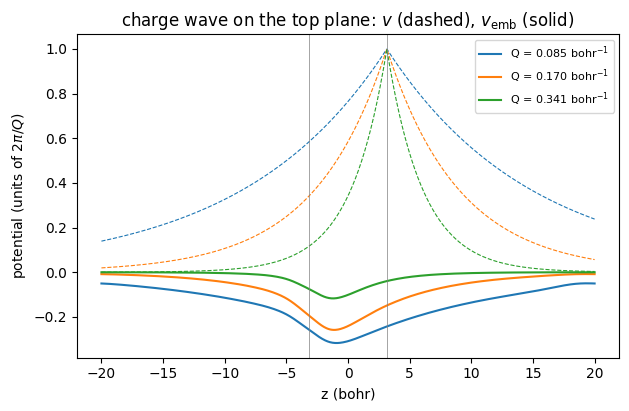

In [5]:
z = np.linspace(-c / 2, c / 2, 801)
fig, ax = plt.subplots(figsize=(7, 4.2))
for iq in [2, 3, 5]:
    Q = np.linalg.norm(bot.inplane_Q(iq)[:2])
    vemb = bot.planar(induced(iq, bot.get_X(iq)[0]), iq, (0, 0), z, z_top)[:, 0].real * Q / (2 * np.pi)
    l, = ax.plot(z, vemb, label='Q = %.3f bohr$^{-1}$' % Q)
    ax.plot(z, np.exp(-Q * abs(z - z_top)), '--', color=l.get_color(), lw=0.8)
    print('Q = %.3f bohr^-1: on the top plane v_emb/v = %.3f' % (Q, np.interp(z_top, z, vemb)))
for zz in (z_bot, z_top):
    ax.axvline(zz, color='gray', lw=0.5)
ax.set_xlabel('z (bohr)')
ax.set_ylabel('potential (units of $2\\pi/Q$)')
ax.set_title('charge wave on the top plane: $v$ (dashed), $v_{\\rm emb}$ (solid)')
ax.legend(fontsize=8)
plt.show()

- $v$ (dashed) decays as $e^{-Q|z - z_t|}$: the smaller $Q$, the farther it reaches and the more it polarizes the
  bottom layer.
- $v_{\mathrm{emb}}$ (solid) is negative (the substrate weakens the interaction), largest at the bottom layer, and above
  it decays as $e^{-Qz}$.
- On the top plane $\tilde v = v + v_{\mathrm{emb}}$ is reduced by 24%, 15% and 4% at these three $Q$.

**$v$ and $\tilde v$ on the top plane** ($z = z' = z_t$), for all the $\mathbf Q = \mathbf q + \mathbf G_\parallel$ of
the grid, static and at $i\,27$ eV.

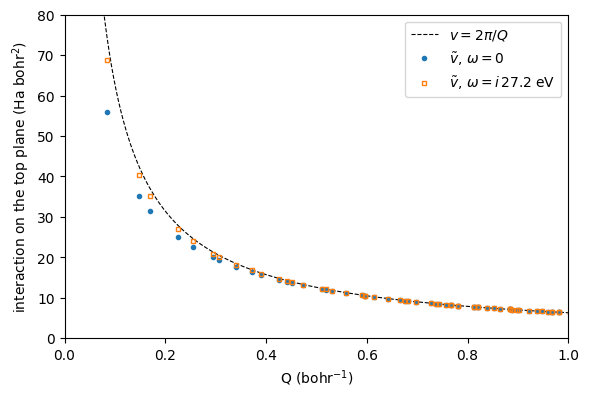

Q (bohr^-1)            0.085  0.148  0.170  0.225  0.256  0.295
v (Ha bohr^2)          73.76  42.59  36.88  27.88  24.59  21.29
vt, w = 0               55.84  35.17  31.39  25.12  22.66  20.08
vt, w = i 27 eV         68.88  40.33  35.17  26.99  23.96  20.90


In [6]:
vt_rows = []                                             # (iq, Q, vt/v at w = 0, vt/v at i 27 eV)
for iq in range(2, bot.nq + 1):
    vemb = induced(iq, bot.get_X(iq))                    # both frequencies
    for G_par, idx in blocks.items():
        if len(idx) >= 15:                               # enough G_z to resolve z
            Q = np.linalg.norm(bot.inplane_Q(iq, G_par)[:2])
            vt_rows.append((iq, Q, *(1 + on_top_plane(vemb, iq, G_par))))
vt_rows = np.array(vt_rows)
Qs = vt_rows[:, 1]

fig, ax = plt.subplots(figsize=(6.5, 4.2))
Qline = np.linspace(0.06, 1.0, 200)
ax.plot(Qline, 2 * np.pi / Qline, 'k--', lw=0.8, label='$v = 2\\pi/Q$')
for iw, (mk, wl) in enumerate([('o', r'$\omega = 0$'), ('s', r'$\omega = i\,27.2$ eV')]):
    kw = dict(ms=3) if iw == 0 else dict(ms=3, mfc='none')
    ax.plot(Qs, 2 * np.pi / Qs * vt_rows[:, 2 + iw], mk, label=r'$\tilde v$, ' + wl, **kw)
ax.set_xlim(0, 1.0)
ax.set_ylim(0, 80)
ax.set_xlabel('Q (bohr$^{-1}$)')
ax.set_ylabel('interaction on the top plane (Ha bohr$^2$)')
ax.legend()
plt.show()

first = np.argsort(Qs)[:6]
print('Q (bohr^-1)          ' + ''.join('%7.3f' % x for x in Qs[first]))
print('v (Ha bohr^2)        ' + ''.join('%7.2f' % (2 * np.pi / x) for x in Qs[first]))
for iw, wl in enumerate(['w = 0', 'w = i 27 eV']):
    print('vt, %-12s      ' % wl + ''.join('%7.2f' % x for x in (2 * np.pi / Qs * vt_rows[:, 2 + iw])[first]))

- The substrate weakens the interaction on the top plane only at long wavelengths: $\tilde v$ is below $v$ by 24% at
  the smallest $Q$ of the grid (0.085 bohr$^{-1}$), by 10% at $Q \approx 0.22$, and by less than 1% above
  $Q \approx 0.5$. At $\omega = i\,27$ eV the effect is about three times smaller: the response of the substrate is
  dynamical.
- The points from different $\mathbf q + \mathbf G_\parallel$ fall on one curve of $|\mathbf Q|$, as in Eq. (21).

### 3.2 Planar reading: the surface response function $g(Q)$

Above the charge induced in the substrate, Sec. 2.2 gives $v_{\mathrm{emb}}$ the factorized form of Eq. (24),
$v_{\mathrm{emb}}(Q; z, z') = -(2\pi/Q)\,g(Q)\,e^{-Q(z - z_0)}e^{-Q(z' - z_0)}$: the whole substrate is in the single
function $g(Q, \omega)$, relative to a reference plane $z_0$. We take the midpoint between the layers, $z_0 = 0$ (a
convention: moving the plane changes $g$ into $g\,e^{-2Qz_0}$; between the layers $g$ keeps its meaning, $\le 1$ and
comparable with $\beta$). On the top plane, with $d = z_t - z_0$, the formula after Eq. (24) gives
$$
\frac{\tilde v}{v} = 1 - g(Q)\,e^{-2Qd} \qquad\Rightarrow\qquad g(Q) = \left(1 - \frac{\tilde v}{v}\right)e^{2Qd} .
$$
So $g$ is extracted from the computed $\tilde v$, and Eq. (24) is not assumed: its factorized form is checked by
extracting $g$ at different heights $z = z' = h$.

d = 3.146 bohr. Eq. (24): g extracted at h = 2, 3.15, 5, 8 bohr agrees within 3.2% (8 smallest Q)


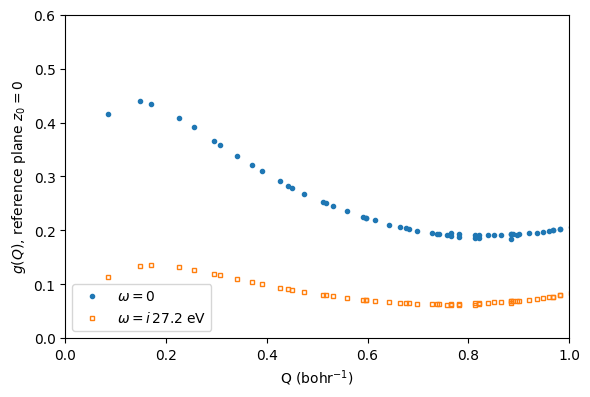

Q (bohr^-1)            0.085  0.148  0.170  0.225  0.256  0.295
g,  w = 0               0.415  0.441  0.435  0.409  0.391  0.366
g,  w = i 27 eV         0.113  0.134  0.135  0.131  0.127  0.119


In [7]:
z_ref = 0.0                                              # reference plane of g: midpoint between the layers
d = z_top - z_ref
g_rows = (1 - vt_rows[:, 2:]) * np.exp(2 * Qs[:, None] * d)

hs = [2.0, z_top, 5.0, 8.0]
spread = []
for iq in sorted(range(2, bot.nq + 1), key=lambda i: np.linalg.norm(bot.q[i - 1]))[:8]:
    Q = np.linalg.norm(bot.inplane_Q(iq)[:2])
    vemb = induced(iq, bot.get_X(iq)[0])
    gs = np.array([-(Q / (2 * np.pi)) * bot.planar(vemb, iq, (0, 0), h, h)[0, 0].real * np.exp(2 * Q * (h - z_ref))
                   for h in hs])
    spread.append((gs.max() - gs.min()) / gs.max())
print('d = %.3f bohr. Eq. (24): g extracted at h = 2, %.2f, 5, 8 bohr agrees within %.1f%% (8 smallest Q)' % (
      d, z_top, 100 * max(spread)))

fig, ax = plt.subplots(figsize=(6.5, 4.2))
for iw, (mk, wl) in enumerate([('o', r'$\omega = 0$'), ('s', r'$\omega = i\,27.2$ eV')]):
    kw = dict(ms=3) if iw == 0 else dict(ms=3, mfc='none')
    ax.plot(Qs, g_rows[:, iw], mk, label=wl, **kw)
ax.set_xlim(0, 1.0)
ax.set_ylim(0, 0.6)
ax.set_xlabel('Q (bohr$^{-1}$)')
ax.set_ylabel(r'$g(Q)$, reference plane $z_0 = 0$')
ax.legend()
plt.show()
print('Q (bohr^-1)          ' + ''.join('%7.3f' % x for x in Qs[first]))
for iw, wl in enumerate(['w = 0', 'w = i 27 eV']):
    print('g,  %-12s      ' % wl + ''.join('%7.3f' % x for x in g_rows[first, iw]))

- The factorized form of Eq. (24) holds: $g$ does not depend on the height at which it is extracted.
- Static $g \approx 0.4$ at long wavelengths, decreasing at larger $Q$; about three times smaller at $i\,27$ eV.
- For a thin substrate $g$ must vanish as $Q \to 0$ (notes, dielectric slab): this happens below the smallest $Q$ of
  the k = 18 grid, which does not sample that region.

### 3.3 The same in real space (a model below the smallest $Q$)

A unit point charge on the top plane. Its laterally averaged $v_{\mathrm{emb}}$ depends only on the in-plane distance
$\rho$, and with Eq. (24) it is a Hankel transform of $g$ (a.u.):
$$
v_{\mathrm{emb}}(\rho) = -\int_0^\infty dQ\; g(Q)\,e^{-2Qd}\,J_0(Q\rho) ,
\qquad \tilde v(\rho) = \frac{1}{\rho} + v_{\mathrm{emb}}(\rho)
$$
(for a dielectric half-space, $g = \beta$, the image potential of Eq. (26)). Here Eq. (24) is used as a model: the grid
gives $g$ only for $Q \ge Q_{\min} = 0.085$ bohr$^{-1}$. Below, the line uses a polarizable sheet,
$g = r_0Q/(1 + r_0Q)\,e^{-2Q\delta}$, fitted on $Q < 0.5$ bohr$^{-1}$; the band goes from $g$ linear to 0 to $g$
constant, to show the weight of the region the grid does not sample.

w = 0       v_emb(0) = -1.43 eV (band -1.32 to -1.72), from Q < Q_min: 32%


w = i 27 eV v_emb(0) = -0.41 eV (band -0.39 to -0.50), from Q < Q_min: 26%


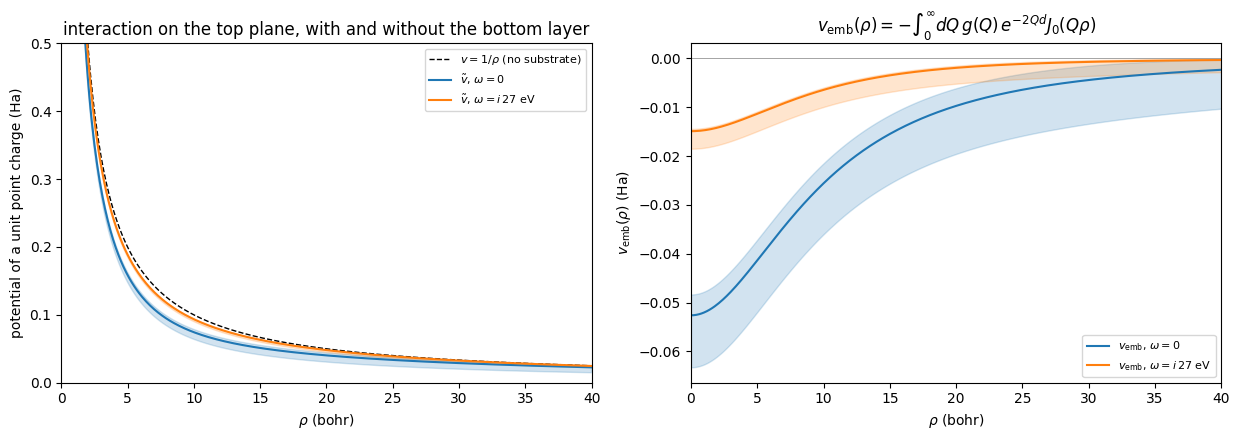

vt/v at rho = 2, 5, 10, 20, 40 bohr (w = 0): 0.90, 0.79, 0.74, 0.81, 0.91
vt/v at rho = 2, 5, 10, 20, 40 bohr (w = i 27 eV): 0.97, 0.94, 0.94, 0.96, 0.99


In [8]:
from scipy.special import j0
from scipy.optimize import curve_fit

def sheet(Q, r0, delta):
    "Polarizable sheet at the depth delta below the reference plane."
    return r0 * Q / (1 + r0 * Q) * np.exp(-2 * Q * delta)

Qf = np.linspace(0, 3.0, 30001)
rho = np.linspace(0, 40, 401)
vemb_rho = {}
for iw in range(2):
    keep = Qs <= 1.0                                     # beyond, e^{-2Qd} < 2e-3 and g is noisy
    Qu = np.unique(np.round(Qs[keep], 4))
    gu = np.array([g_rows[keep, iw][np.round(Qs[keep], 4) == x].mean() for x in Qu])
    fit = curve_fit(sheet, Qu[Qu < 0.5], gu[Qu < 0.5], p0=(10, 1))[0]
    low = Qf < Qu[0]
    for name in ('sheet', 'linear', 'constant'):
        gm = np.interp(Qf, Qu, gu)
        gm[low] = {'sheet': sheet(Qf[low], *fit), 'linear': gu[0] * Qf[low] / Qu[0], 'constant': gu[0]}[name]
        w = gm * np.exp(-2 * Qf * d)
        vemb_rho[iw, name] = -np.trapezoid(w[None, :] * j0(np.outer(rho, Qf)), Qf, axis=1)
        if name == 'sheet':
            share = np.trapezoid(w[low], Qf[low]) / np.trapezoid(w, Qf)
    print('%-11s v_emb(0) = %.2f eV (band %.2f to %.2f), from Q < Q_min: %.0f%%' % (
          'w = 0' if iw == 0 else 'w = i 27 eV', vemb_rho[iw, 'sheet'][0] * HaToeV, vemb_rho[iw, 'linear'][0] * HaToeV,
          vemb_rho[iw, 'constant'][0] * HaToeV, 100 * share))

fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.5))
sel = rho >= 1.0
ax[0].plot(rho[sel], 1 / rho[sel], 'k--', lw=1, label=r'$v = 1/\rho$ (no substrate)')
for iw, col, lab in ((0, 'C0', r'$\omega = 0$'), (1, 'C1', r'$\omega = i\,27$ eV')):
    ax[0].plot(rho[sel], 1 / rho[sel] + vemb_rho[iw, 'sheet'][sel], color=col, label=r'$\tilde v$, ' + lab)
    ax[0].fill_between(rho[sel], 1 / rho[sel] + vemb_rho[iw, 'linear'][sel], 1 / rho[sel] + vemb_rho[iw, 'constant'][sel],
                       color=col, alpha=0.2)
    ax[1].plot(rho, vemb_rho[iw, 'sheet'], color=col, label=r'$v_{\rm emb}$, ' + lab)
    ax[1].fill_between(rho, vemb_rho[iw, 'linear'], vemb_rho[iw, 'constant'], color=col, alpha=0.2)
ax[0].set_ylim(0, 0.5)
ax[0].set_ylabel('potential of a unit point charge (Ha)')
ax[0].set_title('interaction on the top plane, with and without the bottom layer')
ax[1].axhline(0, color='gray', lw=0.5)
ax[1].set_ylabel(r'$v_{\rm emb}(\rho)$ (Ha)')
ax[1].set_title(r'$v_{\rm emb}(\rho) = -\int_0^\infty dQ\, g(Q)\, e^{-2Qd} J_0(Q\rho)$')
for a in ax:
    a.set_xlim(0, 40)
    a.set_xlabel(r'$\rho$ (bohr)')
    a.legend(fontsize=8)
plt.tight_layout()
plt.show()
for iw, wl in enumerate(['w = 0', 'w = i 27 eV']):
    print('vt/v at rho = 2, 5, 10, 20, 40 bohr (%s): ' % wl +
          ', '.join('%.2f' % (1 + x * np.interp(x, rho, vemb_rho[iw, 'sheet'])) for x in (2, 5, 10, 20, 40)))

- $\tilde v$ is below $1/\rho$ by up to about 25%, around $\rho \approx 10$ bohr, and goes back to $1/\rho$ at short
  distances (where $1/\rho$ dominates) and at large distances ($g \to 0$ as $Q \to 0$). At $\omega = i\,27$ eV the
  effect is about four times smaller.
- $v_{\mathrm{emb}}(0) \approx -1.4$ eV (static) is the potential that the charge feels from its own image in the bottom
  layer. About a third of it comes from $Q < Q_{\min}$, where $g$ is modelled: the real-space values are indicative.
- This is not the GW correction: in $W$ the effect of the substrate is screened in turn by the layer itself
  (Sec. 4).

## 4. $W$ of the top layer with the substrate

Eq. (19) in the symmetrized form ($\tilde W = v^{-1/2}Wv^{-1/2}$, $\tilde{\tilde v} = v^{-1/2}\tilde v v^{-1/2} = 1 +
X^{\mathrm S}$, $\tilde\chi_0^{\mathrm L} = 1 - (1 + X^{\mathrm L})^{-1}$):
$$
\tilde W = \left(1 - \tilde{\tilde v}\,\tilde\chi_0^{\mathrm L}\right)^{-1}\tilde{\tilde v} ,
\qquad X^{\mathrm{new}} = \tilde W - 1 = \varepsilon^{-1}_{\mathrm{eff}} - 1 ,
$$
at each $\mathbf q$ and frequency. It needs $\chi^{\mathrm S}$ of the substrate (stored) and $\chi_0^{\mathrm L}$ of the
layer (from its $X$). Both come from the database of `ML_bot` only: $X^{\mathrm S}$ as read, $X^{\mathrm L}$ = the same
$X$ moved onto the top layer (Sec. 2). The same $W$ follows from $\tilde W = (1 - \tilde\chi_0^{\mathrm S} - \tilde\chi_0^{\mathrm L})^{-1}$
(additive $\chi_0$, Eqs. (16)-(17) of the notes): used as a check of the algebra. The physical check is the comparison with the
$X$ of the explicit bilayer, which differs only by the hybridization of the states in $\chi_0$.

$X^{\mathrm{new}}$ is written as a new screening database of the top layer, in a new folder of its run,
`ndb_pp-ngsblkxp_6.0-bndsrnxp_200-emb_ML_bot`, with `write` of MPPI called on the `ML_top` database as template (header
and netCDF layout of the run that will read it): it copies the header and the fragments, replaces $X$, never copies
`ndb.RIM_W` (Yambo recomputes it from the new $X$), rewrites a fragment already on disk only if its content differs
from $X^{\mathrm{new}}$ by more than $10^{-7}$ (single-precision round-off) and reads back what it writes. The original
databases are not touched. The new database is then opened as any other, as a check.

In [9]:
I = np.eye(bot.ng)

def embed(chi0_layer, vt):
    "Eq. (19) of the notes in symmetrized form: X of the layer screened by the substrate (arrays [w, G, G'])."
    return np.linalg.solve(I - vt @ chi0_layer, vt) - I

def X_new(bl, iq, Xb=None):
    "X of the top layer of the stacking bl with the bottom layer as substrate, from the ML_bot database only."
    Xb = bot.get_X(iq) if Xb is None else Xb
    Xt = bot.transform(Xb, iq, rotation=operation[bl], translation=tau[bl])     # top layer (Sec. 2)
    return embed(bot.chi0(iq, Xt), bot.eps_inv(iq, Xb)), Xt

new_db = {bl: os.path.join(MB, run['ML_top_' + bl], 'ndb_pp-ngsblkxp_6.0-bndsrnxp_200-emb_ML_bot') for bl in names}
for bl in names:
    out = scr['ML_top_' + bl].write(new_db[bl], lambda iq, bl=bl: X_new(bl, iq)[0])
    print('%-3s %s: X written at %d q points, %d fragments already up to date' % (
          names[bl], new_db[bl], len(out['written']), len(out['unchanged'])))
emb = {bl: YamboScreeningParser(new_db[bl], os.path.join(MB, run['ML_top_' + bl], 'SAVE'), verbose=False) for bl in names}

W_rows, checks = [], []
for iq in range(1, bot.nq + 1):
    Xb = bot.get_X(iq)
    for bl in names:
        Xnew, Xt = X_new(bl, iq, Xb)
        Xbl = scr[bl].get_X(iq)
        Xdisk = emb[bl].get_X(iq)
        Xsum = np.linalg.inv(I - bot.chi0(iq, Xt) - bot.chi0(iq, Xb)) - I            # additive chi0
        Xnew_run = embed(bot.chi0(iq, scr['ML_top_' + bl].get_X(iq)), bot.eps_inv(iq, Xb))   # computed top layer
        rel = lambda A, B: np.linalg.norm(A - B, axis=(1, 2)) / np.linalg.norm(B, axis=(1, 2))
        r = np.array([abs(Xnew - Xsum).max(axis=(1, 2)), abs(Xdisk - Xnew).max(axis=(1, 2)), rel(Xnew, Xbl),
                      rel(Xt, Xbl), rel(Xnew, Xnew_run)])
        checks += [(bl, iq, iw) + tuple(r[:, iw]) for iw in range(2)]
        if iq > 1:
            M = [induced(iq, X) for X in (Xt, Xnew, Xbl)]                      # alone, effective, bilayer
            for G_par, idx in blocks.items():
                if len(idx) >= 15:
                    Q = np.linalg.norm(bot.inplane_Q(iq, G_par)[:2])
                    W_rows.append((bl, iq, Q) + tuple(1 + on_top_plane(m, iq, G_par)[iw] for m in M for iw in range(2)))

chk = np.array([r[3:] for r in checks])
print('Eq. (19) vs additive chi0, max |dX|: %.1e' % chk[:, 0].max())
print('written vs computed (single precision), max |dX|: %.1e' % chk[:, 1].max())
q0 = np.array([r[1] == 1 for r in checks])
print('X_new from ML_bot only vs X_new with the computed ML_top database: ||dX|| / ||X|| = %.1e at q -> 0, <= %.1e at the other q'
      % (chk[q0, 4].max(), chk[~q0, 4].max()))
for bl in names:
    for iw, wl in enumerate(['w = 0', 'w = i 27 eV']):
        m = np.array([(r[0] == bl and r[2] == iw) for r in checks])
        print('%-3s %-11s ||X - X_bilayer|| / ||X_bilayer||: effective %.3f-%.3f, top layer alone %.3f-%.3f' % (
              names[bl], wl, chk[m, 2].min(), chk[m, 2].max(), chk[m, 3].min(), chk[m, 3].max()))

AA' MB_analysis/kpoints_18-nbnds_250-ML_top_AA1/ndb_pp-ngsblkxp_6.0-bndsrnxp_200-emb_ML_bot: X written at 0 q points, 37 fragments already up to date


AB  MB_analysis/kpoints_18-nbnds_250-ML_top_AB/ndb_pp-ngsblkxp_6.0-bndsrnxp_200-emb_ML_bot: X written at 0 q points, 37 fragments already up to date


Eq. (19) vs additive chi0, max |dX|: 2.3e-15
written vs computed (single precision), max |dX|: 1.5e-08
X_new from ML_bot only vs X_new with the computed ML_top database: ||dX|| / ||X|| = 1.2e-04 at q -> 0, <= 1.4e-05 at the other q
AA' w = 0       ||X - X_bilayer|| / ||X_bilayer||: effective 0.004-0.023, top layer alone 0.684-0.706
AA' w = i 27 eV ||X - X_bilayer|| / ||X_bilayer||: effective 0.002-0.003, top layer alone 0.699-0.706
AB  w = 0       ||X - X_bilayer|| / ||X_bilayer||: effective 0.003-0.020, top layer alone 0.684-0.706
AB  w = i 27 eV ||X - X_bilayer|| / ||X_bilayer||: effective 0.002-0.003, top layer alone 0.699-0.706


**$W$ on the plane of the top layer** ($W/v$, laterally averaged as in Sec. 3): the top layer alone, with the
substrate (effective) and in the explicit bilayer.

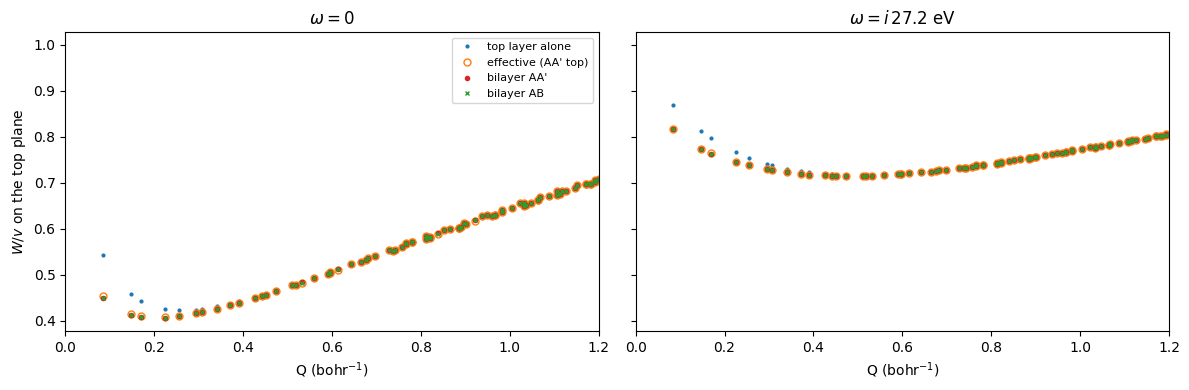

AA' w = 0       max |effective - bilayer| = 0.0034, max |alone - bilayer| = 0.0929 (units of v)
AA' w = i 27 eV max |effective - bilayer| = 0.0002, max |alone - bilayer| = 0.0542 (units of v)
AB  w = 0       max |effective - bilayer| = 0.0035, max |alone - bilayer| = 0.0929 (units of v)
AB  w = i 27 eV max |effective - bilayer| = 0.0003, max |alone - bilayer| = 0.0542 (units of v)


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for iw, wl in enumerate([r'$\omega = 0$', r'$\omega = i\,27.2$ eV']):
    for bl, mk in [('AA1', 'o'), ('AB', 'x')]:
        r = np.array([row[2:] for row in W_rows if row[0] == bl])
        if bl == 'AA1':
            ax[iw].plot(r[:, 0], r[:, 1 + iw], '.', color='C0', ms=4, label='top layer alone')
            ax[iw].plot(r[:, 0], r[:, 3 + iw], 'o', color='C1', ms=5, mfc='none', label="effective (AA' top)")
        ax[iw].plot(r[:, 0], r[:, 5 + iw], mk, color='C3' if bl == 'AA1' else 'C2', ms=3, label='bilayer ' + names[bl])
    ax[iw].set_title(wl)
    ax[iw].set_xlabel('Q (bohr$^{-1}$)')
    ax[iw].set_xlim(0, 1.2)
ax[0].set_ylabel('$W / v$ on the top plane')
ax[0].legend(fontsize=8)
plt.tight_layout()
plt.show()
for bl in names:
    r = np.array([row[2:] for row in W_rows if row[0] == bl])
    for iw, wl in enumerate(['w = 0', 'w = i 27 eV']):
        print('%-3s %-11s max |effective - bilayer| = %.4f, max |alone - bilayer| = %.4f (units of v)' % (
              names[bl], wl, abs(r[:, 3 + iw] - r[:, 5 + iw]).max(), abs(r[:, 1 + iw] - r[:, 5 + iw]).max()))

- Eq. (19) and the additive form give the same $X$ (round-off), and the database on disk is the computed one within
  single precision. Built from `ML_bot` alone, $X^{\mathrm{new}}$ equals the one obtained with the computed `ML_top`
  database at the level of Sec. 2 ($\sim 10^{-5}$, $10^{-4}$ at $\mathbf q \to 0$).
- The effective $W$ is the $W$ of the explicit bilayer: on the top plane within 0.004 $v$ ($\omega = 0$) and 0.0003
  $v$ ($i\,27$ eV), against a substrate effect of up to 0.09 $v$ (the layer alone). The full matrices agree within
  0.3-2.3% (largest at $q \to 0$), against about 70% for the layer alone. The two stackings give the same effective $W$ on
  the plane, as expected (the registry enters only the $\mathbf G_\parallel \ne \mathbf G_\parallel'$ terms).
- So in this benchmark the screening is not the issue: the hybridization of the states, which the effective scheme
  does not have, barely changes $\chi_0$. The differences between the effective and the explicit GW will come from the
  states (the Green's function), not from $W$.

## 5. Next: GW of the top layer with the new database

To run (after agreeing with the user): the GW of `ML_top_AA1` and `ML_top_AB` with the converged parameters and the
input of their runs, with `ndb_pp-ngsblkxp_6.0-bndsrnxp_200-emb_ML_bot` in place of the original screening folder in
the `jobname` list, and no `ndb.RIM_W` from earlier runs (recomputed). First at the checked points ($\Gamma$, K), then
on the full IBZ; then the GW corrections of the top layer, effective vs extracted from the bilayer
(`results/layer_projection.json`).